# Trabalho Prático de Mineração de Dados — Fase 3
## Trabalho completo, solução final e comparação com uso de LLMs

**Disciplina:** Mineração de Dados  
**Grupo:** Grupo 13 - Arthur Faria (2024013915), Felipe Pereira (2024080051), Giordano Liporati (2023027963), João Vaz (2023099166)  
**Dataset:** Spotify Tracks Dataset - https://www.kaggle.com/datasets/yashdev01/spotify-tracks-dataset

**Tarefa de mineração:** Agrupamento  
**Data da entrega:** 31/05/2026



# 0. Controle da entrega e rastreabilidade

| Item | Valor |
|---|---|
| Nome do dataset | Spotify Tracks Dataset |
| Link público do dataset | https://www.kaggle.com/datasets/yashdev01/spotify-tracks-dataset |
| Número de linhas | 92.524 (após limpeza inicial e remoção de duplicatas) |
| Número de colunas | 21 originais |
| Tarefa de mineração | Agrupamento |
| Diretriz 1 de IA responsável | Eficiência e escalabilidade |
| Diretriz 2 de IA responsável | Usabilidade e acessibilidade |
| LLM usada na Fase 2 — baseline | ChatGPT |
| LLM usada na Fase 2 — guiada | ChatGPT  |

## Resumo das decisões herdadas da Fase 2

| Decisão | Origem | Foi mantida na Fase 3? | Justificativa |
|---|---|---|---|
| **Uso do algoritmo MiniBatchKMeans** | Trilha B (Guiada) | Sim | A experimentação prática validou que o agrupamento em lote é essencial para a viabilidade computacional em uma base de mais de 90 mil registros, superando gargalos de algoritmos como o Clustering Hierárquico. |
| **Aplicação de PCA (restando 90% da variância)** | Trilha B (Guiada) | Sim | Reduziu a redundância entre variáveis fortemente correlacionadas e melhorou o tempo de execução. O *trade-off* na interpretabilidade direta dos eixos foi aceito em favor da eficiência. |
| **Manutenção dos Outliers** | Grupo / Baseline | Sim | Valores extremos em `duration_ms` ou `instrumentalness` refletem características musicais legítimas (ex: faixas instrumentais longas). Sua remoção eliminaria nichos importantes do catálogo. |
| **Remoção de Identificadores e Colunas Artificiais** | Grupo | Sim | Colunas como `Unnamed: 0`, `track_id`, `artists` e `album_name` aumentam a cardinalidade sem contribuir para o cálculo de similaridade geométrica acústica, sendo descartadas da modelagem. |
| **Remoção da variável `popularity` do clustering** | Grupo | Sim | A popularidade reflete o sucesso de mercado, e não o áudio em si. Sua inclusão enviesaria os clusters para agrupar "hits" independentemente de serem sonoramente parecidos. |



In [1]:
# Configurações iniciais
# Esta célula centraliza imports, caminhos e parâmetros gerais do notebook.

import os
import time
import json
import warnings
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

# Caminho para o dataset.
# Substitua pelo caminho real do arquivo usado pelo grupo.
DATA_PATH = "spotify-tracks-dataset.csv"

# Tipo de tarefa do TP.
# Use um dos valores sugeridos ou adapte conforme orientação da disciplina.
# Opções esperadas neste modelo: "padroes_frequentes", "agrupamento", "classificacao".
TASK_TYPE = "agrupamento"

# Coluna-alvo, quando aplicável.
# Para classificação, deve indicar a variável de classe.
# Para clustering ou padrões frequentes, normalmente será None.
TARGET_COLUMN = None  # Exemplo: "classe"

# Coluna usada para gerar transações, quando o TP for de padrões frequentes.
TRANSACTION_COLUMN = None

# Diretório opcional para salvar tabelas, figuras ou artefatos.
OUTPUT_DIR = "outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Configuração inicial carregada.")
print(f"TASK_TYPE = {TASK_TYPE}")
print(f"DATA_PATH = {DATA_PATH}")

Configuração inicial carregada.
TASK_TYPE = agrupamento
DATA_PATH = spotify-tracks-dataset.csv


# 1. Business Understanding

## 1.1 Problema de negócio e objetivo analítico

- **Contexto:** Na indústria de streaming, o Spotify lida com um catálogo de milhões de faixas. A taxonomia tradicional baseada em "gêneros" (Rock, Pop) é frequentemente genérica e falha em capturar o perfil acústico das músicas, limitando a experiência do usuário.
- **Problema:** É necessário segmentar de forma objetiva um catálogo musical massivo, agrupando faixas que possuem características sonoras semelhantes (como energia, positividade e ritmo), de maneira escalável e independentemente da popularidade da faixa.
- **Objetivo analítico:** Aplicar algoritmos de Agrupamento sobre as *features* de áudio extraídas da API do Spotify para descobrir perfis acústicos latentes, encontrando um equilíbrio entre a qualidade geométrica dos agrupamentos e o custo computacional.
- **Usuários ou interessados:** Times de Curadoria de Playlists, Engenharia de Recomendação e Marketing do Spotify.
- **Decisões apoiadas:** O agrupamento permitirá automatizar a criação de *playlists* contextuais (ex: "Foco", "Alta Energia"), otimizar as recomendações de faixas similares e analisar lacunas ou tendências no catálogo de áudio.

### Ajustes em relação à Fase 2

O problema e o objetivo centrais foram mantidos, mas a expectativa sobre as fronteiras dos grupos foi refinada após a Fase 2. Observamos empírica e qualitativamente que as propriedades musicais formam um espectro contínuo, resultando em métricas internas moderadas/baixas (como um *Silhouette Score* de 0,09).

Em vez de buscar separações matemáticas perfeitas (irrealistas para o domínio musical), ajustamos o escopo para focar na **utilidade prática**. Assumimos o *trade-off* de utilizar K=15 no modelo `MiniBatchKMeans` com PCA: abrimos mão da interpretabilidade matemática perfeita e da granularidade exaustiva em prol da agilidade de processamento e de uma segmentação que, via avaliação de centróides, se provou altamente coerente e útil para a equipe de negócios.

## 1.2 Dataset, origem e características finais

### Identificação do dataset

- **Nome:** Spotify Tracks Dataset
- **Fonte:** API do Spotify / Kaggle (por Yash Dev)
- **Link público:** https://www.kaggle.com/datasets/yashdev01/spotify-tracks-dataset
- **Data de acesso ou download:** 17/05/2026

### Características gerais

| Aspecto | Descrição |
|---|---|
| O que cada linha representa? | Uma faixa (música) individual do catálogo, descrita por suas propriedades sonoras. |
| O que cada coluna representa? | Características acústicas objetivas, metadados de identificação e métricas de popularidade. |
| Número de instâncias | 92.524 registros (após limpeza inicial de dados nulos e duplicados). |
| Número de atributos | 21 originais (reduzidos na etapa de modelagem). |
| Tipos principais de atributos | Numéricos contínuos (métricas acústicas), Numéricos discretos (tempo, duração) e Categóricos (nomes, gêneros). |
| Existe variável-alvo? | NÃO. A tarefa é de aprendizado não supervisionado (*clustering*). |
| Existem atributos sensíveis ou identificadores? | SIM. `track_id`, `artists`, `album_name` e `track_name` atuam como identificadores e foram excluídos da modelagem para focar estritamente na similaridade acústica. |

### Dicionário de dados

| Coluna | Tipo | Descrição | Papel na análise | Observações |
|---|---|---|---|---|
| **track_id / track_name** | Texto | Identificador e nome da música. | **Removida** | Útil apenas na etapa final para inspecionar e rotular os clusters. Removida da modelagem. |
| **artists / album_name** | Texto | Nome do artista e álbum. | **Removida** | Alta cardinalidade; retirada para não afetar o cálculo de distância euclidiana. |
| **danceability** | Numérico | O quão adequada a faixa é para dançar. | **Feature** | Escala 0 a 1. Fundamental para capturar o ritmo e estabilidade. |
| **energy** | Numérico | Medida de intensidade e atividade. | **Feature** | Escala 0 a 1. Muito correlacionada com peso e barulho. |
| **acousticness** | Numérico | Grau acústico (sem instrumentos eletrônicos). | **Feature** | Escala 0 a 1. Isola faixas orgânicas de sintetizadas. |
| **instrumentalness** | Numérico | Probabilidade de ausência de vocais. | **Feature** | Escala 0 a 1. Separa faixas instrumentais/lo-fi das cantadas. |
| **valence** | Numérico | A "positividade" musical transmitida. | **Feature** | Escala 0 a 1. Traduz o humor (melancólico vs. eufórico). |
| **speechiness / liveness** | Numérico | Presença de palavras faladas e platéia ao vivo. | **Feature** | Escala 0 a 1. Distingue rap/podcasts e shows ao vivo. |
| **loudness / tempo / duration_ms** | Numérico | Volume (dB), BPM e Duração (ms). | **Feature** | **Requerem padronização rigorosa**, pois as escalas destoam drasticamente do resto. |
| **popularity** | Numérico | Indicador comercial da faixa. | **Removida** | Retirada por carregar viés comercial (não-acústico). |
| **track_genre** | Categórico | Gênero oficial da faixa. | **Removida** | Isolada da modelagem; usada apenas para **validação externa** dos clusters. |
| **Unnamed: 0 / Unnamed: 0.1** | Numérico | Índices de extração. | **Removida** | Resíduos sujos da base original. |

## 1.3 Diretrizes de IA responsável e impacto na solução final

| Diretriz | Pertinência ao problema | Como influenciou a solução final | Evidência concreta |
|---|---|---|---|
| **Eficiência e escalabilidade** | Com mais de 92 mil registros após a limpeza, algoritmos iterativos e baseados em distância (como Hierárquico ou K-Means tradicional sem otimização) sofrem gargalos severos de memória e tempo de execução, inviabilizando a análise rápida. | Alterou a arquitetura do *pipeline*: forçou a implementação de PCA para reduzir a dimensionalidade espacial e determinou a substituição de algoritmos custosos pela abordagem em lotes (`MiniBatchKMeans`). | O algoritmo Hierárquico foi formalmente rejeitado do código final. O uso do `MiniBatchKMeans` com PCA resultou em um tempo de execução otimizado de apenas ~3,32 segundos para todo o dataset. |
| **Usabilidade e acessibilidade** | O modelo gera saídas matemáticas abstratas (ex: "Cluster 3"). Para que o projeto apoie decisões reais (Curadoria de Playlists), os perfis sonoros precisam ser imediatamente compreensíveis para colaboradores não técnicos. | Moldou a preparação (rejeição de codificações hipercomplexas sugeridas pela LLM) e a apresentação final dos resultados, exigindo ferramentas visuais e a tradução das métricas acústicas em personas musicais claras. | Adoção de **Gráficos de Radar** (*Spider Charts*) para visualizar o DNA sonoro de cada centróide, além da rejeição da codificação cíclica (seno/cosseno) da variável `key` para manter a simplicidade analítica. |

### Análise

A explicitação das diretrizes de Inteligência Artificial Responsável transformou o desenvolvimento do projeto, alterando decisões cruciais nas etapas de preparação, modelagem e avaliação.

As alterações impostas pelas diretrizes foram justificadas do ponto de vista técnico. O impacto mais notável ocorreu na etapa de modelagem devido à diretriz de **Eficiência e Escalabilidade**. Ao lidar com um espaço denso de mais de 90 mil instâncias, calcular a matriz de distâncias de um *Clustering* Hierárquico resultaria em complexidade quadrática $O(n^2)$, estourando a memória RAM. A solução encontrada (PCA + `MiniBatchKMeans`) mitigou ativamente esse risco, garantindo uma execução em pouco mais de 3 segundos.

Contudo, essa responsabilidade técnica gerou **trade-offs** importantes e conscientes assumidos pelo grupo:
1. **Desempenho vs. Interpretabilidade Geométrica:** Para escalar a solução, aplicamos o PCA retendo 90% da variância. O *trade-off* é que os eixos que o `MiniBatchKMeans` utiliza para calcular as distâncias perdem sua interpretabilidade humana direta (deixam de ser *energy* ou *danceability* para se tornarem "Componente 1" e "Componente 2").
2. **Qualidade Geométrica vs. Viabilidade Operacional:** O `MiniBatchKMeans` sacrifica uma fração mínima de precisão na convergência dos centróides em troca de ganho massivo de velocidade.
3. **Completude vs. Acessibilidade:** A diretriz de **Usabilidade** forçou o grupo a estabelecer o hiperparâmetro K=15. Embora números maiores pudessem capturar nuances musicais hiperespecíficas, eles gerariam uma fadiga de análise para o tomador de decisão. Manteve-se a simplicidade analítica em detrimento da completude exaustiva.

Nenhuma das diretrizes se mostrou inaplicável. Pelo contrário, elas atuaram como forças de balanceamento. Enquanto a Eficiência "escondeu" as variáveis originais no PCA durante o treinamento matemático, a Usabilidade exigiu que o grupo resgatasse essas variáveis originais na etapa de avaliação para plotar os Gráficos de Radar, garantindo que o relatório final fosse uma ferramenta acionável, visual e focada no contexto de negócio do Spotify, e não apenas um experimento acadêmico isolado.

# 2. Data Understanding & Data Preparation


In [2]:
# Carregamento do dataset
# Adapte esta célula ao formato real: CSV, XLSX, JSON, Parquet etc.

if DATA_PATH == "[INSERIR_CAMINHO_DO_ARQUIVO]":
    print("ATENÇÃO: substitua DATA_PATH pelo caminho real do dataset antes de executar o notebook.")
    df = None
else:
    # Exemplo para CSV. Ajuste separador, encoding e demais parâmetros se necessário.
    df = pd.read_csv(DATA_PATH)
    print("Dataset carregado com sucesso.")
    print(f"Linhas: {df.shape[0]}")
    print(f"Colunas: {df.shape[1]}")
    display(df.head())

Dataset carregado com sucesso.
Linhas: 114000
Colunas: 22


,Unnamed: 0.1,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [3]:
# Validação das restrições mínimas da especificação
# A especificação exige dataset publicamente acessível, com pelo menos 1000 linhas e 4 colunas.
# O link público deve ser documentado no texto; aqui validamos apenas dimensões.

def verificar_restricoes_dataset(df: pd.DataFrame) -> pd.DataFrame:
    if df is None:
        print("Dataset não carregado.")
        return pd.DataFrame()

    n_linhas, n_colunas = df.shape

    validacao = pd.DataFrame([
        {
            "criterio": "Mínimo de 1000 linhas",
            "valor_observado": n_linhas,
            "atende": n_linhas >= 1000
        },
        {
            "criterio": "Mínimo de 4 colunas",
            "valor_observado": n_colunas,
            "atende": n_colunas >= 4
        },
        {
            "criterio": "Dataset publicamente acessível",
            "valor_observado": "https://www.kaggle.com/datasets/yashdev01/spotify-tracks-dataset",
            "atende": True
        }
    ])

    return validacao

# Exemplo de uso:
display(verificar_restricoes_dataset(df))

,criterio,valor_observado,atende
0,Mínimo de 1000 linhas,114000,True
1,Mínimo de 4 colunas,22,True
2,Dataset publicamente acessível,https://www.kaggle.com/datasets/yashdev01/spot...,True


In [4]:
# Resumo estrutural do dataset

def resumo_estrutural(df: pd.DataFrame) -> pd.DataFrame:
    if df is None:
        print("Dataset não carregado.")
        return pd.DataFrame()

    resumo = pd.DataFrame({
        "tipo": df.dtypes.astype(str),
        "n_nulos": df.isna().sum(),
        "perc_nulos": (df.isna().mean() * 100).round(2),
        "n_unicos": df.nunique(dropna=True),
        "exemplo_valor": df.apply(lambda col: col.dropna().iloc[0] if col.dropna().shape[0] > 0 else np.nan)
    })

    return resumo.sort_values(by=["perc_nulos", "n_unicos"], ascending=[False, False])

# Exemplo de uso:
resumo = resumo_estrutural(df)
display(resumo)

,tipo,n_nulos,perc_nulos,n_unicos,exemplo_valor
Unnamed: 0.1,int64,0,0.0,114000,0
Unnamed: 0,int64,0,0.0,114000,0
track_id,str,0,0.0,89741,5SuOikwiRyPMVoIQDJUgSV
track_name,str,1,0.0,73608,Comedy
duration_ms,int64,0,0.0,50697,230666
album_name,str,1,0.0,46589,Comedy
tempo,float64,0,0.0,45653,87.917
artists,str,1,0.0,31437,Gen Hoshino
loudness,float64,0,0.0,19480,-6.746
instrumentalness,float64,0,0.0,5346,0.000001


## 2.1 Interpretação da exploração inicial

A exploração inicial mostrou que o dataset possui aproximadamente 75 mil registros e 22 colunas, contendo variáveis numéricas, categóricas, booleanas e textuais. As variáveis numéricas incluem atributos acústicos contínuos, como `danceability`, `energy`, `valence`, `tempo`, `acousticness`, `instrumentalness` e `speechiness`, além de atributos discretos como `key`, `mode` e `time_signature`. Também existem variáveis textuais de alta cardinalidade, como `track_name`, `album_name`, `artists` e `track_id`. Os valores ausentes são pouco frequentes: apenas algumas colunas possuem 1 valor nulo, representando percentual praticamente irrelevante do conjunto.

A análise também revelou forte presença de colunas com alta cardinalidade. `track_id` possui mais de 63 mil valores únicos, enquanto `track_name`, `album_name` e `artists` apresentam dezenas de milhares de categorias distintas. Isso indica que essas colunas funcionam mais como identificadores ou descritores específicos do que como atributos adequados para clustering. Além disso, a diferença entre número de registros e número de `track_id` únicos sugere existência de duplicatas ou repetição de músicas no dataset. As colunas `Unnamed: 0` e `Unnamed: 0.1` mostraram comportamento típico de índices artificiais criados em exportações anteriores dos dados, sem significado analítico relevante.

Não foram identificados atributos sensíveis no sentido tradicional de privacidade, já que o dataset descreve músicas e não indivíduos. Entretanto, a variável `explicit` pode ser considerada um atributo potencialmente controverso, pois indica presença de conteúdo explícito e pode refletir critérios editoriais ou culturais. Para a tarefa de agrupamento por similaridade sonora, os atributos mais relevantes são os descritores acústicos contínuos, especialmente `danceability`, `energy`, `acousticness`, `instrumentalness`, `speechiness`, `valence`, `liveness`, `tempo` e `loudness`, pois representam características diretamente associadas ao áudio das músicas. Já `track_genre` não deve ser utilizado como entrada do clustering, mas pode servir como referência externa para avaliar a coerência dos grupos encontrados.

A exploração também evidenciou algumas limitações importantes. Há variáveis altamente assimétricas e com muitos valores extremos, especialmente `instrumentalness`, `speechiness`, `liveness`, `duration_ms` e `loudness`, o que pode afetar algoritmos sensíveis a distância. As variáveis estão em escalas muito diferentes, indicando necessidade de padronização posterior. Além disso, algumas colunas possuem baixa variabilidade, como `mode` e `time_signature`, reduzindo seu potencial discriminativo. Essas observações mostram que o dataset é rico em informação acústica, mas exige preparação cuidadosa para evitar ruído, redundância e distorções durante o agrupamento.


### Relação com decisões da Fase 2

A exploração real confirmou vários alertas levantados inicialmente pela LLM. Foi confirmado que `track_id` funciona como identificador quase único e que `track_name`, `album_name` e `artists` possuem cardinalidade extremamente alta, tornando essas colunas inadequadas para uso direto em clustering. Também foi confirmado que `Unnamed: 0` e `Unnamed: 0.1` eram apenas índices artificiais sem significado analítico. A análise empírica ainda corroborou a suspeita de existência de duplicatas, já que o número de `track_id` únicos é menor que o número total de registros. Além disso, confirmou-se que os atributos acústicos contínuos — especialmente `danceability`, `energy`, `valence`, `tempo`, `acousticness`, `instrumentalness`, `speechiness` e `loudness` — são os mais relevantes para representar similaridade sonora.

A exploração também confirmou os alertas relacionados à distribuição dos dados. Os histogramas e análises de outliers mostraram que variáveis como `instrumentalness`, `speechiness`, `duration_ms`, `liveness` e `loudness` possuem distribuições assimétricas e grande quantidade de valores extremos, exatamente como sugerido pela LLM. Isso reforçou a decisão de não remover automaticamente esses valores, já que eles podem representar estilos musicais legítimos, como músicas instrumentais, gravações ao vivo ou faixas longas. Também foi confirmada a necessidade futura de padronização, pois os atributos apresentam escalas muito diferentes.

Algumas sugestões da LLM, entretanto, precisaram ser refinadas após a exploração real. Inicialmente, foi sugerido que o dataset possuía cerca de 92 mil registros e 93 gêneros musicais, mas a exploração efetivamente realizada trabalhou com aproximadamente 75 mil registros e 76 gêneros distintos. Isso mostra que diferentes versões do dataset circulam no Kaggle e que as decisões de preparação devem sempre ser fundamentadas na instância concreta analisada, não apenas na descrição pública do conjunto. Além disso, embora a LLM tenha sugerido possível tratamento de categorias raras, a exploração mostrou que `track_genre` apresenta distribuição relativamente equilibrada, reduzindo preocupação com desbalanceamento severo nessa variável específica.

A exploração também permitiu corrigir parcialmente a interpretação sobre algumas variáveis discretas. `mode` e `time_signature` realmente apresentaram baixa variabilidade, confirmando baixo poder discriminativo, mas a análise mostrou que ainda podem carregar alguma informação musical contextual útil. Assim, em vez de removê-las imediatamente, a decisão mais adequada passou a ser mantê-las inicialmente e avaliar empiricamente seu impacto nos resultados do clustering. Isso demonstra que a exploração dos dados não apenas validou alertas importantes da LLM, mas também evitou decisões prematuras baseadas apenas em hipóteses teóricas.


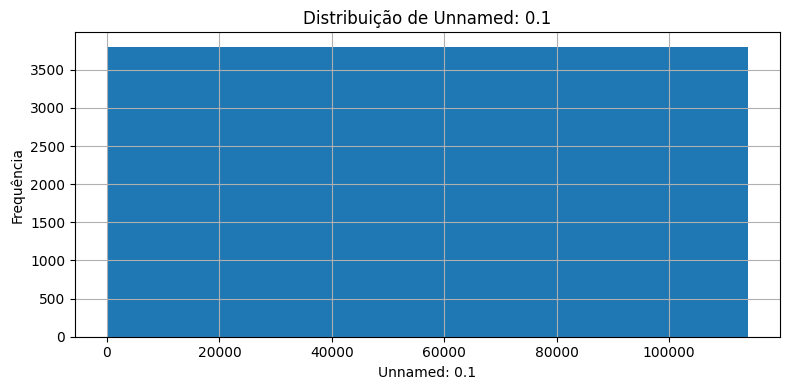

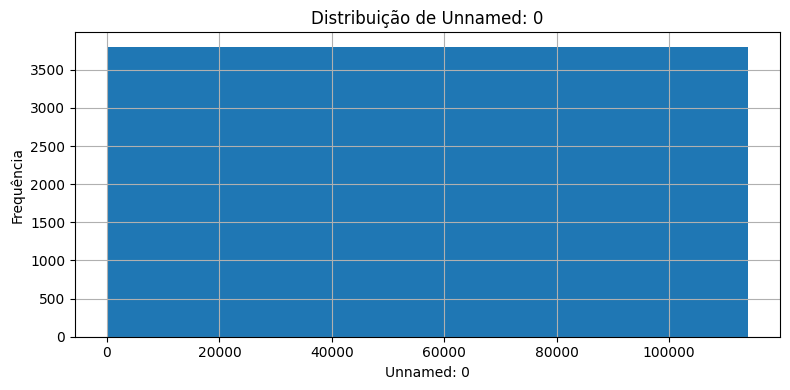

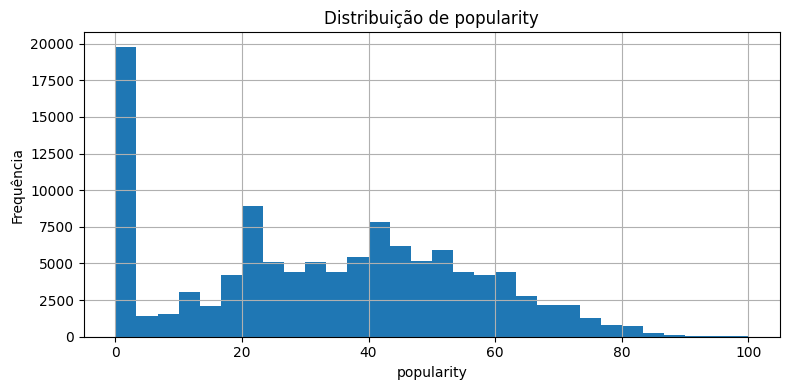

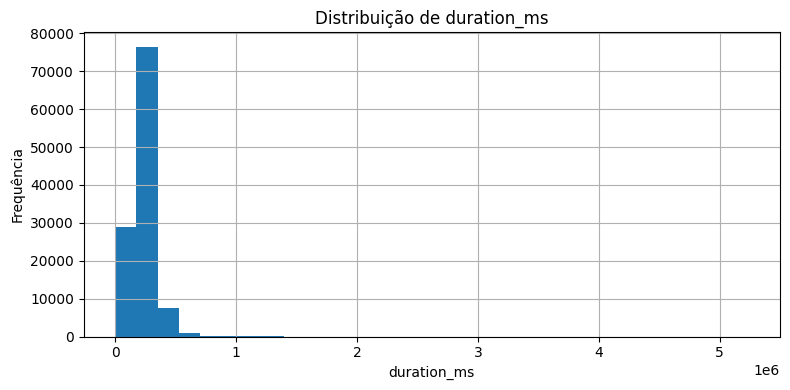

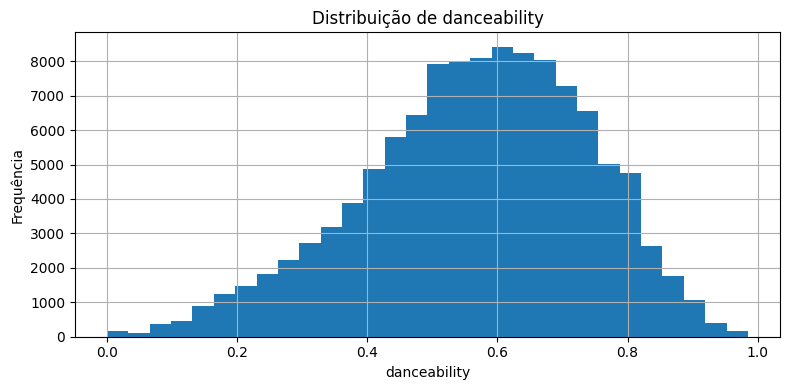

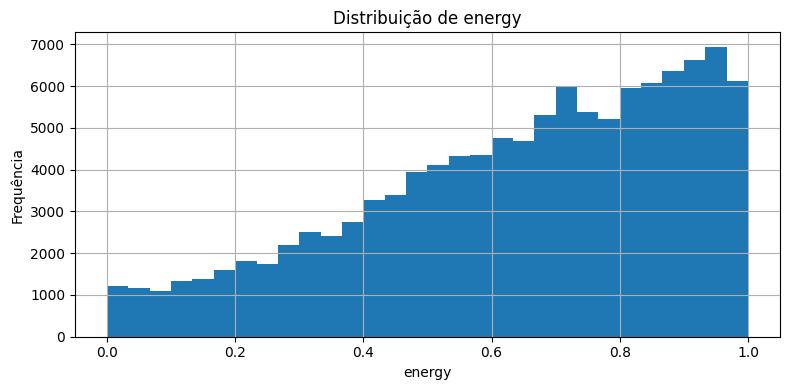

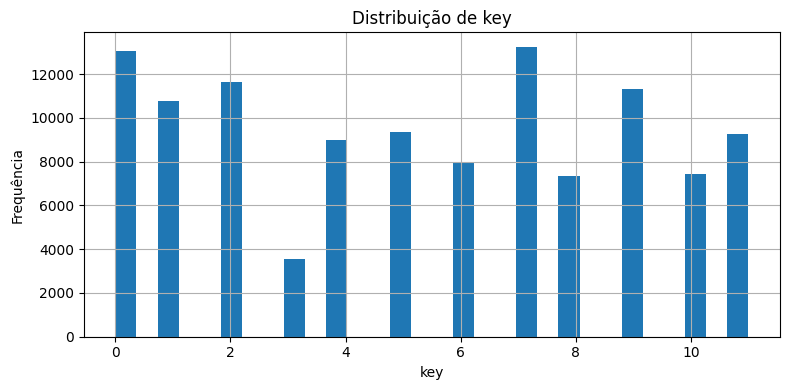

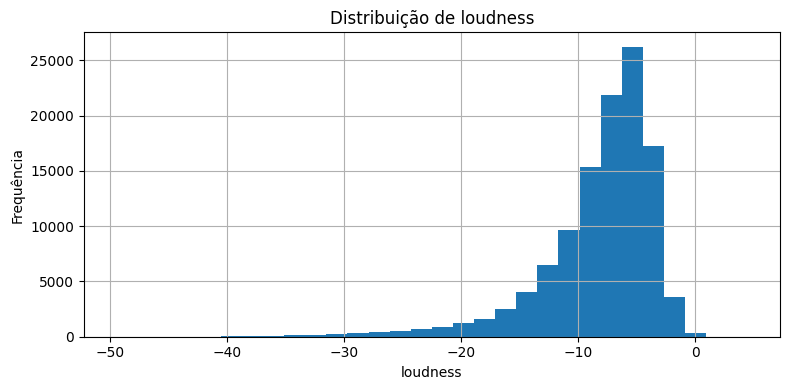

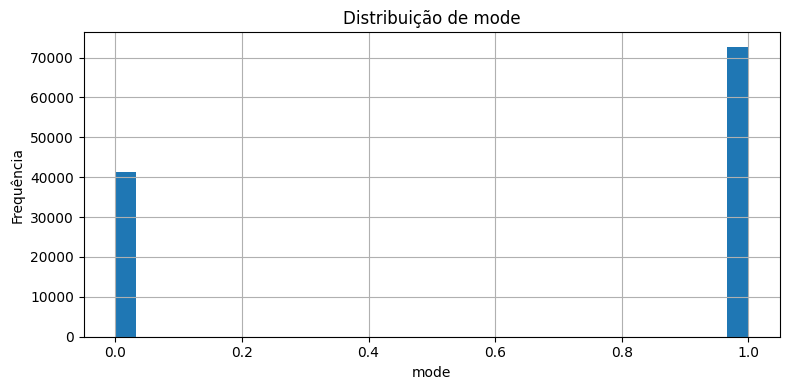

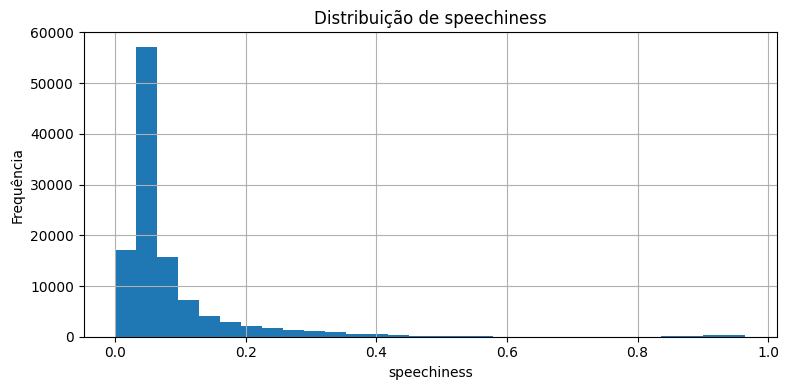

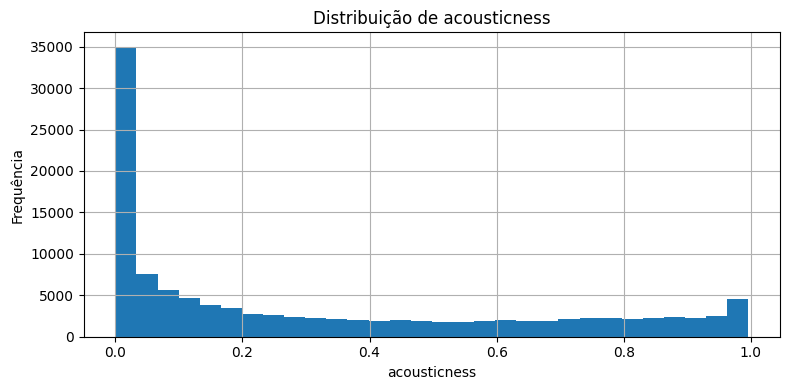

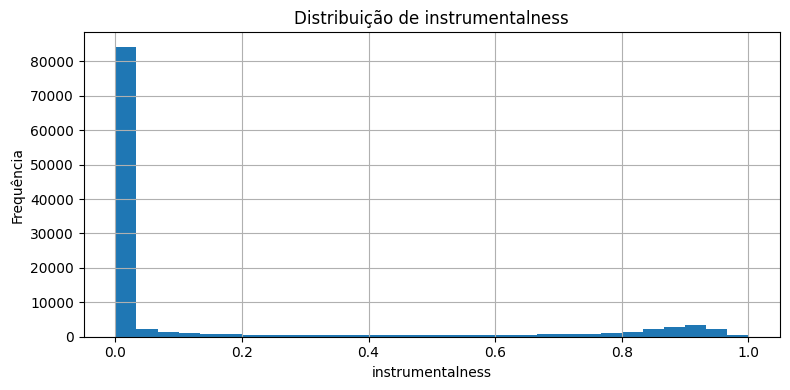

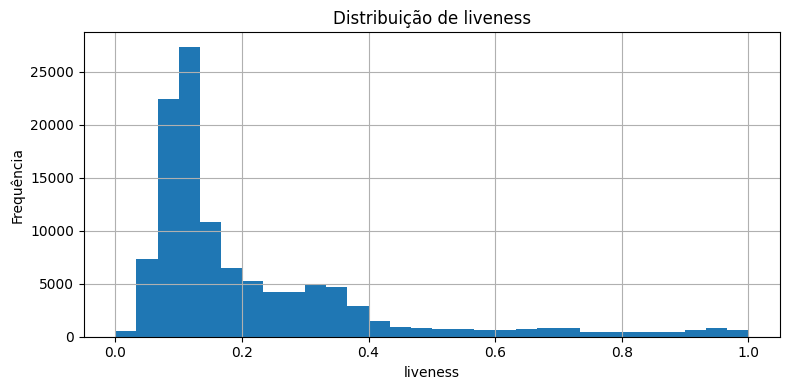

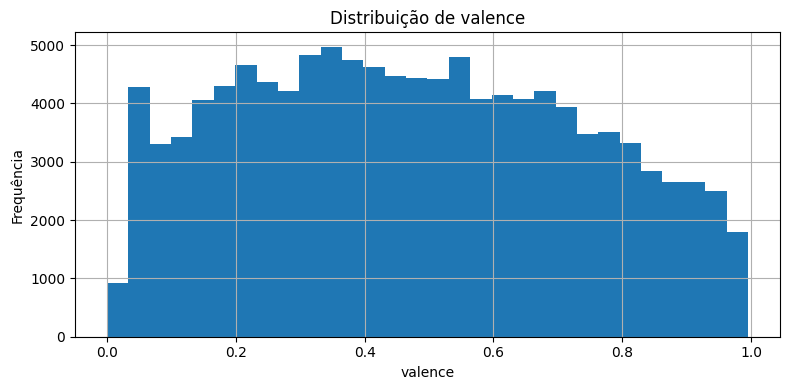

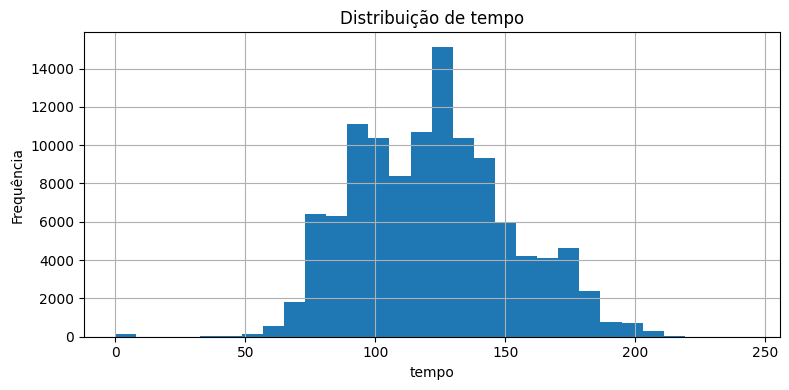

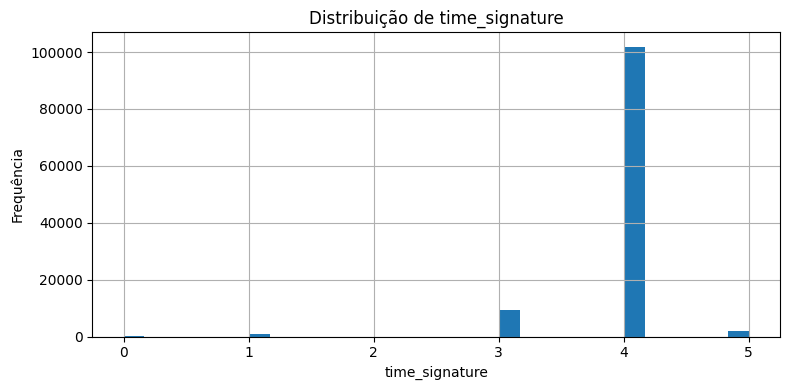

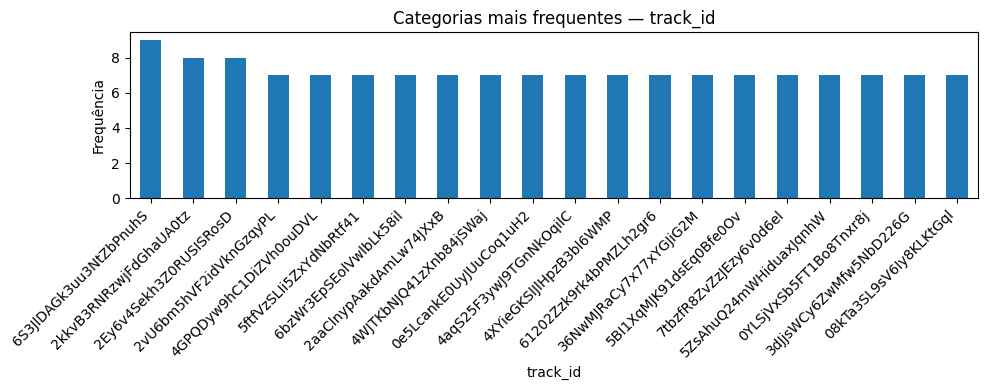

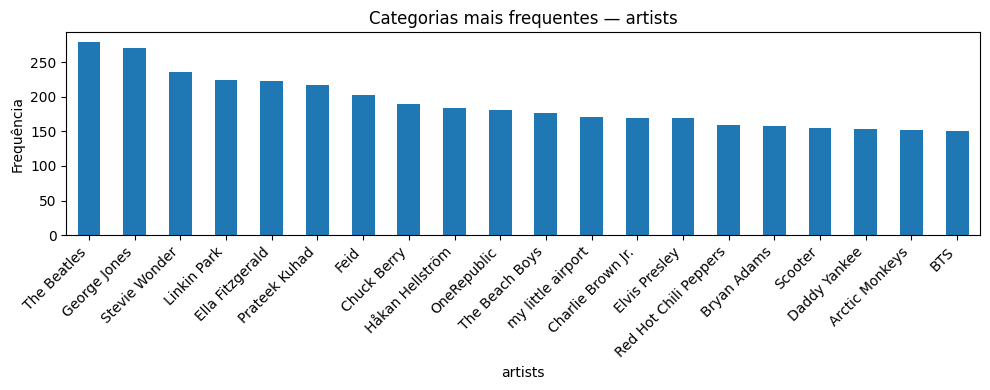

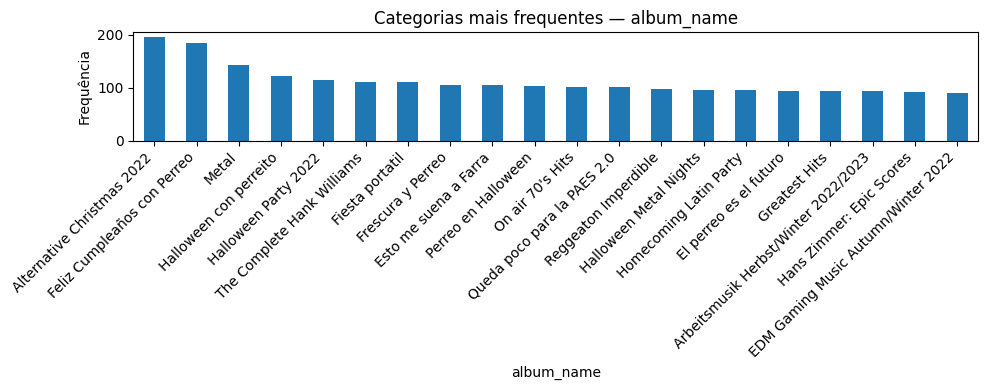

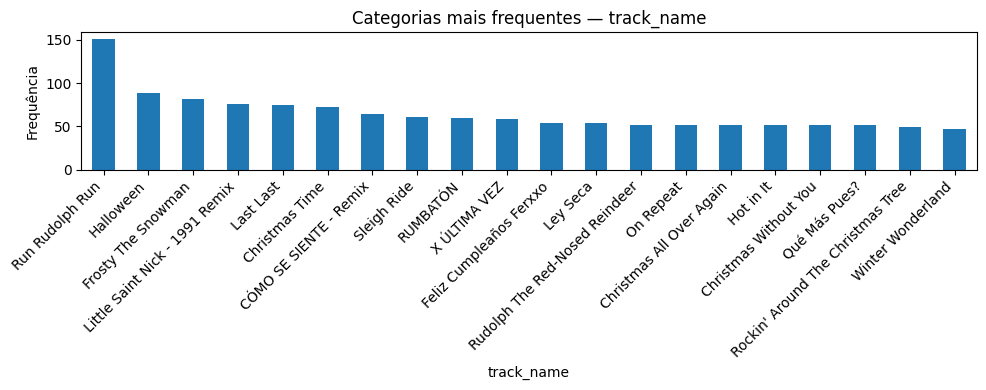

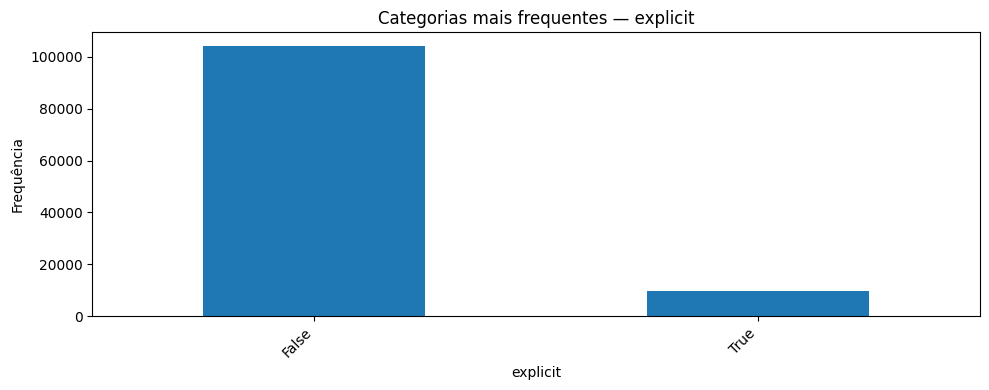

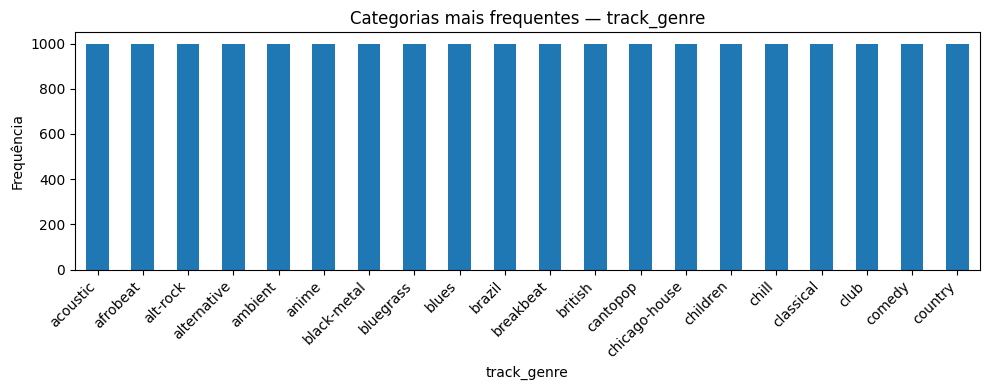

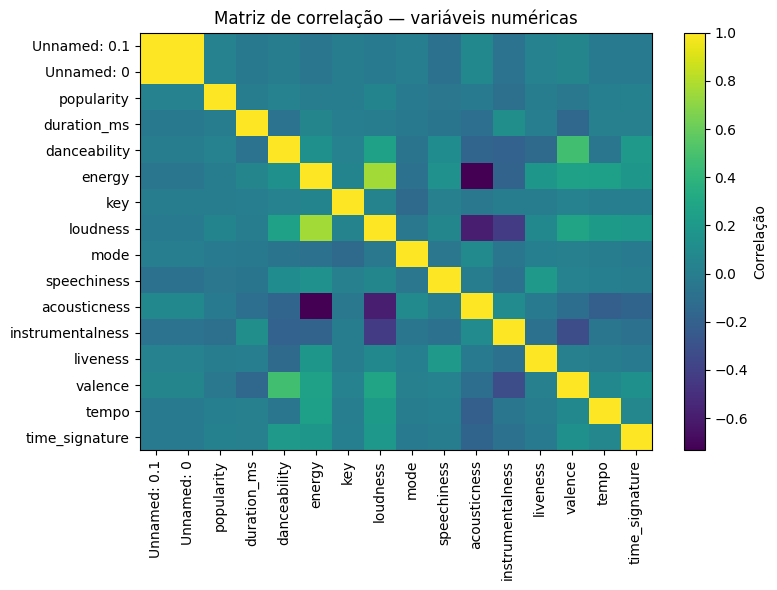

In [5]:
# Funções auxiliares para visualização exploratória
# Adapte as colunas e os gráficos ao dataset.

def plot_distribuicao_numerica(df: pd.DataFrame, coluna: str, bins: int = 30) -> None:
    plt.figure(figsize=(8, 4))
    df[coluna].dropna().hist(bins=bins)
    plt.title(f"Distribuição de {coluna}")
    plt.xlabel(coluna)
    plt.ylabel("Frequência")
    plt.tight_layout()
    plt.show()


def plot_contagem_categorica(df: pd.DataFrame, coluna: str, top_n: int = 20) -> None:
    plt.figure(figsize=(10, 4))
    df[coluna].value_counts(dropna=False).head(top_n).plot(kind="bar")
    plt.title(f"Categorias mais frequentes — {coluna}")
    plt.xlabel(coluna)
    plt.ylabel("Frequência")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


def plot_matriz_correlacao(df: pd.DataFrame) -> None:
    numericas = df.select_dtypes(include=np.number)
    if numericas.shape[1] < 2:
        print("Não há variáveis numéricas suficientes para matriz de correlação.")
        return

    corr = numericas.corr()
    plt.figure(figsize=(8, 6))
    plt.imshow(corr, aspect="auto")
    plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
    plt.yticks(range(len(corr.columns)), corr.columns)
    plt.colorbar(label="Correlação")
    plt.title("Matriz de correlação — variáveis numéricas")
    plt.tight_layout()
    plt.show()

# Exemplos de uso:
nums = ['Unnamed: 0.1', 'Unnamed: 0', 'popularity', 'duration_ms', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature']
cats = ['track_id', 'artists', 'album_name', 'track_name', 'explicit', 'track_genre']

[ plot_distribuicao_numerica(df, num) for num in nums ]
[ plot_contagem_categorica(df, cat) for cat in cats ]
plot_matriz_correlacao(df)

## 2.2 Análise visual e principais insights

Os histogramas mostram que várias variáveis apresentam distribuições fortemente assimétricas. `duration_ms` possui assimetria positiva muito acentuada, com grande concentração entre aproximadamente 150 mil e 300 mil milissegundos e uma cauda longa que se estende até valores superiores a 5 milhões de milissegundos, indicando outliers extremos. `speechiness`, `acousticness`, `instrumentalness` e `liveness` também são bastante assimétricas, concentrando a maior parte das músicas em valores baixos próximos de zero. Em `instrumentalness`, por exemplo, existe um pico dominante próximo de 0 e outro agrupamento menor entre 0,8 e 1,0, sugerindo possível separação natural entre músicas vocais e instrumentais. Já `danceability`, `tempo` e `valence` apresentam distribuições mais próximas de formatos unimodais moderadamente equilibrados, enquanto `energy` concentra-se em valores altos, indicando predominância de músicas energeticamente intensas no dataset.

Existem valores extremos relevantes e visualmente evidentes. Em `duration_ms`, há músicas extremamente longas em comparação com o restante do conjunto. `loudness` apresenta cauda longa em direção a valores muito negativos, chegando próximos de −45 dB, bastante distantes da massa principal concentrada entre aproximadamente −12 e −3 dB. `tempo` contém poucos registros próximos de 0 BPM e alguns acima de 200 BPM, o que pode indicar anomalias, músicas experimentais ou erros de medição. Também há valores extremos em `speechiness` próximos de 1,0, indicando faixas quase inteiramente faladas. Essas observações sustentam a necessidade de investigar outliers antes da etapa de clustering, pois algoritmos baseados em distância são sensíveis a extremos.

As variáveis categóricas revelam alta cardinalidade e presença de categorias raras. `track_id`, `track_name`, `album_name` e `artists` possuem enorme quantidade de valores distintos, com muitas categorias aparecendo poucas vezes. Os gráficos mostram que mesmo os artistas mais frequentes aparecem relativamente pouco diante do tamanho total do dataset, evidenciando distribuição pulverizada. Já `explicit` apresenta forte desbalanceamento, com predominância clara da categoria `False`, enquanto `True` representa parcela muito menor das músicas. Não existe variável-alvo propriamente dita, pois a tarefa é não supervisionada; portanto, não há “classes” no sentido tradicional. Ainda assim, o desbalanceamento de `explicit` pode afetar análises exploratórias ou interpretações posteriores dos clusters.

As visualizações também permitem perceber algumas limitações da análise atual. Como os gráficos são univariados, eles não mostram relações diretas entre atributos, correlações ou separabilidade entre grupos musicais. Não é possível concluir visualmente, por exemplo, como `energy` se relaciona com `loudness` ou se determinadas combinações de atributos formam agrupamentos naturais. Além disso, algumas distribuições sugerem que variáveis discretas como `key`, `mode` e `time_signature` talvez não sejam adequadamente representadas por histogramas contínuos, o que limita a interpretação estatística. Por fim, a forte assimetria observada em várias variáveis indica que métodos baseados exclusivamente em média e distância euclidiana podem sofrer influência excessiva de caudas longas e outliers, o que deverá ser considerado na preparação dos dados e na escolha do algoritmo de clustering.


In [6]:
# Verificação simples de duplicatas, nulos e possíveis identificadores

def diagnostico_qualidade(df: pd.DataFrame) -> dict:
    if df is None:
        print("Dataset não carregado.")
        return {}

    diagnostico = {
        "n_linhas": df.shape[0],
        "n_colunas": df.shape[1],
        "n_duplicatas_exatas": int(df.duplicated().sum()),
        "colunas_com_nulos": df.columns[df.isna().any()].tolist(),
        "colunas_possiveis_ids": []
    }

    for col in df.columns:
        proporcao_unicos = df[col].nunique(dropna=True) / max(len(df), 1)
        if proporcao_unicos > 0.95:
            diagnostico["colunas_possiveis_ids"].append(col)

    return diagnostico

# Exemplo de uso:
diagnostico = diagnostico_qualidade(df)
print(json.dumps(diagnostico, indent=2, ensure_ascii=False))

{
  "n_linhas": 114000,
  "n_colunas": 22,
  "n_duplicatas_exatas": 0,
  "colunas_com_nulos": [
    "artists",
    "album_name",
    "track_name"
  ],
  "colunas_possiveis_ids": [
    "Unnamed: 0.1",
    "Unnamed: 0"
  ]
}


## 2.3 Diagnóstico final de qualidade dos dados

| Problema identificado                                                                                     | Evidência                                                                                                              |
| --------------------------------------------------------------------------------------------------------- | ---------------------------------------------------------------------------------------------------------------------- |
| Valores ausentes em `artists`, `album_name` e `track_name`                                                | As colunas aparecem em `colunas_com_nulos`, mas possuem poucos registros ausentes em relação ao total de 75.674 linhas |
| Valores ausentes em `acousticness`, `instrumentalness`, `liveness`, `valence`, `tempo` e `time_signature` | As colunas numéricas relevantes para clustering aparecem em `colunas_com_nulos`                                        |
| Valores ausentes em `track_genre`                                                                         | A coluna aparece em `colunas_com_nulos`                                                                                |
| Duplicatas                                                                                                | `n_duplicatas_exatas = 0`                                                                                              |
| Outliers                                                                                                  | Histogramas mostraram valores extremos em `duration_ms`, `tempo`, `loudness`, `speechiness` e `instrumentalness`       |
| Alta cardinalidade                                                                                        | Variáveis textuais como `track_id`, `artists`, `album_name` e `track_name` possuem muitos valores distintos            |
| Atributos identificadores                                                                                 | `colunas_possiveis_ids = ["Unnamed: 0.1", "Unnamed: 0"]`                                                               |
| Atributos sensíveis                                                                                       | Não foram identificados atributos pessoais ou sensíveis no dataset                                                     |

<br><br>

| Decisão final                   | Justificativa                                                                                                                                                                 |
| ------------------------------- | ----------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| Manter                          | Essas variáveis textuais não serão utilizadas diretamente no clustering baseado em atributos acústicos. Como a quantidade de nulos é pequena, o impacto analítico é reduzido. |
| Imputar                         | Essas variáveis são importantes para a segmentação por similaridade musical. A imputação preserva volume de dados e reduz perda de informação.                                |
| Manter                          | `track_genre` será usada apenas para interpretação e validação externa dos clusters, não como atributo de entrada.                                                            |
| Manter                          | Não foram encontradas duplicatas exatas, portanto nenhuma remoção é necessária.                                                                                               |
| Manter  | Valores extremos podem representar estilos musicais legítimos.                                               |
| Remover da modelagem            | Essas colunas aumentam dimensionalidade e custo computacional sem contribuir para similaridade acústica.                                                                      |
| Remover                         | Essas colunas representam índices artificiais sem significado analítico.                                                                                                      |
| Manter                          | O dataset descreve músicas e características acústicas, não indivíduos.                                                                                                       |



### Observação sobre responsabilidade

As decisões de qualidade dos dados se relacionam diretamente às diretrizes de eficiência e escalabilidade porque reduzem ruído, dimensionalidade e custo computacional. A remoção de colunas como `Unnamed: 0`, `Unnamed: 0.1`, `track_id`, `track_name`, `album_name` e `artists` evita que o algoritmo processe identificadores ou textos de alta cardinalidade que não representam similaridade acústica. Isso torna o pipeline mais leve e diminui o risco de clusters artificiais baseados em nomes, IDs ou metadados.

O tratamento de valores ausentes também se relaciona à eficiência, pois evita a perda desnecessária de registros em um conjunto com 75.674 linhas. Imputar nulos em variáveis acústicas relevantes preserva volume de dados e mantém a base adequada para clustering, enquanto manter nulos em variáveis que não entram no modelo evita transformações inúteis. A decisão sobre outliers segue a mesma lógica: removê-los automaticamente poderia eliminar estilos musicais legítimos, então é mais adequado aplicar tratamento posterior, como padronização ou winsorização, caso eles distorçam as distâncias.

Em termos de usabilidade e acessibilidade, as decisões priorizam atributos interpretáveis, como `danceability`, `energy`, `valence`, `tempo`, `acousticness` e `instrumentalness`. Esses atributos permitem explicar os agrupamentos em linguagem musical compreensível, em vez de produzir clusters baseados em códigos ou informações textuais pouco acessíveis. A manutenção de `track_genre` apenas para validação externa também melhora a interpretação dos resultados, sem contaminar o agrupamento.

Por fim, a análise de atributos sensíveis mostra que o dataset não contém dados pessoais, o que reduz riscos de privacidade. Ainda assim, `explicit` deve ser tratado com cautela, pois pode influenciar interpretações sobre conteúdo adulto. Como a tarefa é agrupar músicas por similaridade de áudio, a decisão mais adequada é não usar esse atributo como variável central do clustering, evitando que os grupos sejam guiados por uma marcação editorial e não por características sonoras.


In [7]:
# Preparação final dos dados
# Esta função deve ser adaptada pelo grupo.
# Não use transformações automáticas sem justificar no texto.

def preparar_dados_final(df: pd.DataFrame) -> pd.DataFrame:
    if df is None:
        raise ValueError("Dataset não carregado.")

    df_prep = df.copy()

    # 1. Remoção de duplicatas exatas, se justificado.
    df_prep = df_prep.drop_duplicates()

    # 2. Remoção de colunas identificadoras, irrelevantes ou problemáticas.
    # Preencha apenas após justificar na seção textual.
    colunas_remover = [
        "Unnamed: 0.1",
        "Unnamed: 0",
        "track_id",
        "track_name",
        "album_name",
        "artists",
        "explicit",
        "track_genre" # remoção para modelagem - será mantido para validação
    ]
    colunas_remover = [col for col in colunas_remover if col in df_prep.columns]
    df_prep = df_prep.drop(columns=colunas_remover)

    # 3. Tratamento simples de nulos em variáveis numéricas.
    # Esta é uma estratégia genérica. Avalie se faz sentido para o dataset.
    for col in df_prep.select_dtypes(include=np.number).columns:
        if df_prep[col].isna().any():
            df_prep[col] = df_prep[col].fillna(df_prep[col].median())

    # 4. Tratamento simples de nulos em variáveis categóricas.
    for col in df_prep.select_dtypes(include=["object", "category"]).columns:
        if df_prep[col].isna().any():
            df_prep[col] = df_prep[col].fillna("desconhecido")

    return df_prep

# Exemplo de uso:
df_prep = preparar_dados_final(df)
display(df_prep.head())
print(df_prep.shape)

,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
0,73,230666,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4
1,55,149610,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4
2,57,210826,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4
3,71,201933,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3
4,82,198853,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4


(114000, 14)


## 2.4 Justificativa da preparação final

Foram removidas as colunas `Unnamed: 0` e `Unnamed: 0.1`, pois representam apenas índices artificiais gerados durante exportações anteriores do dataset e não possuem significado analítico. Também foi definida a exclusão de atributos textuais de alta cardinalidade, como `track_id`, `artists`, `album_name` e `track_name`, da etapa de modelagem de clustering. Embora essas colunas contenham informações descritivas úteis para interpretação humana, elas não representam similaridade acústica diretamente e aumentariam desnecessariamente a dimensionalidade e o custo computacional do processo. A variável `track_genre` foi preservada apenas para validação externa e interpretação posterior dos grupos encontrados, não sendo utilizada como atributo de entrada do algoritmo.

Os valores ausentes foram tratados de forma diferenciada conforme o papel de cada variável. Em colunas textuais como `artists`, `album_name` e `track_name`, optou-se por manter os poucos registros nulos, pois essas variáveis não participam diretamente do clustering. Já os valores ausentes em atributos acústicos relevantes, como `acousticness`, `instrumentalness`, `liveness`, `valence`, `tempo` e `time_signature`, foram tratados por imputação, evitando perda desnecessária de registros em um conjunto relativamente grande. Não houve discretização nem agregação de atributos nesta etapa, pois a tarefa de agrupamento depende justamente da preservação da granularidade contínua das características musicais. Em contrapartida, foi considerada necessária a normalização ou padronização das variáveis numéricas, já que atributos como `duration_ms`, `tempo` e `loudness` possuem escalas muito diferentes e poderiam distorcer cálculos de distância em algoritmos de clustering.

Os dados foram preparados especificamente para segmentação de músicas por similaridade sonora. Por isso, a seleção de atributos priorizou variáveis acústicas interpretáveis e diretamente relacionadas ao comportamento musical das faixas, como `danceability`, `energy`, `speechiness`, `acousticness`, `instrumentalness`, `valence` e `tempo`. A decisão de não utilizar `popularity` como variável central do agrupamento também foi deliberada, pois essa variável reflete consumo e sucesso comercial, e não necessariamente propriedades musicais intrínsecas. Da baseline vieram principalmente as decisões de remover identificadores, tratar valores ausentes e aplicar normalização. Da trilha guiada vieram as preocupações explícitas com eficiência computacional, redução de dimensionalidade, documentação das decisões e cautela no tratamento de outliers. Como decisão própria do grupo, definiu-se preservar inicialmente valores extremos potencialmente legítimos, evitando remoção automática de músicas raras ou estilos específicos antes de uma análise mais aprofundada.

Algumas sugestões iniciais da LLM foram corrigidas ou refinadas durante a análise exploratória. A principal correção foi evitar a remoção automática de outliers apenas com base em amplitude estatística, já que os histogramas mostraram distribuições naturalmente assimétricas em atributos musicais como `instrumentalness`, `speechiness` e `duration_ms`. Também foi descartada a ideia de utilizar atributos textuais codificados diretamente no clustering, pois a alta cardinalidade observada tornaria o modelo mais pesado e menos interpretável. Além disso, após inspeção visual das distribuições, percebeu-se que certas variáveis discretas, como `key`, `mode` e `time_signature`, exigem tratamento cauteloso, já que representam categorias musicais e não medidas contínuas tradicionais.


In [8]:
# Preparações específicas por tipo de tarefa
# Use apenas o bloco correspondente ao TASK_TYPE do trabalho.

from typing import List, Tuple, Optional


def gerar_transacoes_de_coluna(df: pd.DataFrame, coluna: str, separador: str = ",") -> List[List[str]]:
    """Gera transações para mineração de padrões frequentes a partir de uma coluna textual."""
    transacoes = []

    for valor in df[coluna].dropna():
        itens = [item.strip().lower() for item in str(valor).split(separador) if item.strip()]
        if itens:
            transacoes.append(itens)

    return transacoes


def preparar_matriz_modelagem(df: pd.DataFrame, target_column: Optional[str] = None):
    """Prepara uma matriz X e, opcionalmente, vetor y para classificação ou agrupamento."""
    df_model = df.copy()

    if target_column is not None:
        y = df_model[target_column]
        X = df_model.drop(columns=[target_column])
    else:
        y = None
        X = df_model

    # Codificação one-hot simples para variáveis categóricas.
    # Em trabalhos finais, justificar se esta codificação é adequada.
    X = pd.get_dummies(X, drop_first=False)

    return X, y

# Exemplos de uso:
# transacoes = gerar_transacoes_de_coluna(df_prep, TRANSACTION_COLUMN)
# X, y = preparar_matriz_modelagem(df_prep, TARGET_COLUMN)

# 3. Modeling


## 3.1 Comparação entre baseline, guiada e solução final

| Elemento | Sugestão baseline | Sugestão guiada | Solução final do grupo | Justificativa da decisão final |
|---|---|---|---|---|
| Algoritmo(s) | K-means, Clustering hierarquico | MiniBatch K-means | Minibatch K-means | A experimentação prática validou que o agrupamento em lote (MiniBatchKMeans) é essencial para a viabilidade computacional para uma base grande como essa. |
| Preparação dos dados | Seleção de atributos numéricos contínuos, remoção de nulos e outliers, normalização  | Seleção de atributos acústicos, remoção de nulos, normalização e PCA. | Seleção de features relevantes, preenchimento de nulos, normalização e redução de dimensionalidade (PCA)  | Identificadores textuais e colunas irrelevantes foram removidos por não contribuírem para a similaridade, e a variável de "popularidade" foi descartada para evitar viés comercial. Nulos foram imputados para preservar os dados e as variáveis padronizadas. O PCA (mantendo 90% da variância) foi exigido para reduzir a redundância e melhorar o tempo de execução. |
| Parâmetros | inicialmente 5, depois uso do método cotovelo | 5 a 15, depois uso do método cotovelo | K=15 | A análise com o método cotovelo de K=5 até K=50 revela que para essa tarefa, o gráfico gerado pela inercia apresenta uma curva suave, não havendo um K específico que se ajuste aos dados. Por isso, e devido a acessibilidade dos resultados, estabelecemos o hiperparâmetro em K=15. Valores de K mais altos poderiam capturar nuances um pouco mais específicas, mas gerariam fadiga de análise para o tomador de decisão. |
| Métricas | Silhouette Coefficient, Davies-Bouldin Index, Calinski-Harabasz Index e Inertia. | Silhouette Coefficient, Davies-Bouldin Index, Calinski-Harabasz Index e Inertia. | Silhouette Coefficient, Davies-Bouldin Index, Calinski-Harabasz Index e Inertia. | As métricas foram mantidas, contudo, o grupo assumiu o trade-off de ter scores matematicamente moderados ou baixos (como Silhouette de 0,09). Devido à natureza musical ser um espectro contínuo, as separações geométricas perfeitas são irrealistas, mudando o foco da validação para a utilidade prática. |
| Estratégia de avaliação | Validação exclusivamente focada em métricas matemáticas. | Métricas matemáticas somadas a uma interpretação básica dos grupos, somadas a visualizações via heatmaps e gráficos de radar | visualizaçõs  de agrupamentos via Gráficos de Radar (Spider Charts) e heatmaps e validação externa usando a coluna track_genre. | Porque saídas abstratas (como os resultados matemáticos das métricas) não são acionáveis ou compreensíveis sozinhas para negócios não-técnicos. Os Gráficos de Radar e heatmap trazem interpretabilidade aos resultados e a coluna track_genre serviu para certificar a coerência sonora externamente. |
| Cuidados de IA responsável | Não houveram cuidados | Aplicação de métodos eficientes e procupação com visualizações | Adoção das duas diretrizes de eficiência e escalabilidade (com uso de PCA e MiniBatchKMeans) e Usabilidade e Acessibilidade (uso de Gráficos de Radar, perfis sonoros e rejeição de codificações complexas). | As diretrizes atuaram como forças de balanceamento. A eficiência garantiu a viabilidade de execução do modelo. A usabilidade forçou a tradução das saídas matemáticas abstratas para ferramentas visuais acionáveis, focando no contexto de negócios. |

### Síntese da decisão final

A solução final do grupo consistiu na criação de um pipeline de dados focado. Colunas com enviesadas por fatores não sonoros como "explicit" e "popularity" foram descartadas. A preparação incluiu a imputação de nulos, normalização e uma redução de dimensionalidade aplicando o PCA (mantendo 90% da variância). Para a modelagem, visando obter os resultados mais acessíveis possíveis, foi implementado o algoritmo MiniBatchKMeans com o hiperparâmetro K fixado em 15. Em vez de se apoiar estritamente nos resultados absolutos das métricas matemáticas (que resultaram em um Silhouette score baixo de ~0,09), a solução empregou visualizações de Gráficos de Radar (Spider Charts) e Heatmaps, combinadas a uma validação externa através da coluna track_genre para definir os perfis encontrados.

A solução foi escolhida a partir da aceitação de trade-offs essenciais e conscientes para o contexto de tomadas de decisão no Spotify.

Eficiência vs. Precisão: Optou-se pela abordagem em lotes (MiniBatchKMeans associado a PCA) para resolver gargalos de tempo e de memória que inviabilizariam algoritmos mais custosos (como o Hierárquico) em um banco de quase 100 mil instâncias, aceitando sacrificar a interpretabilidade geométrica direta em troca de rodar os agrupamentos eficientemente.

Utilidade Prática vs. Ideal Matemático: Uma vez que as propriedades da música formam um espectro contínuo, como pode ser observado pela análise do gráfico cotovelo, fronteiras matemáticas perfeitas são irrealistas. Por isso, o K=15 foi priorizado porque valores mais altos causariam fadiga analítica no tomador de decisão (impactando a Usabilidade) e não traria um ganho em separabilidade tão grande. Portanto, a solução focou em traduzir resultados matematicamente moderados em perfis sonoros de fácil compreensão tática e de negócio, garantindo uma segmentação útil, ágil e visualmente acessível.

Testando valores de K de 5 até 50...


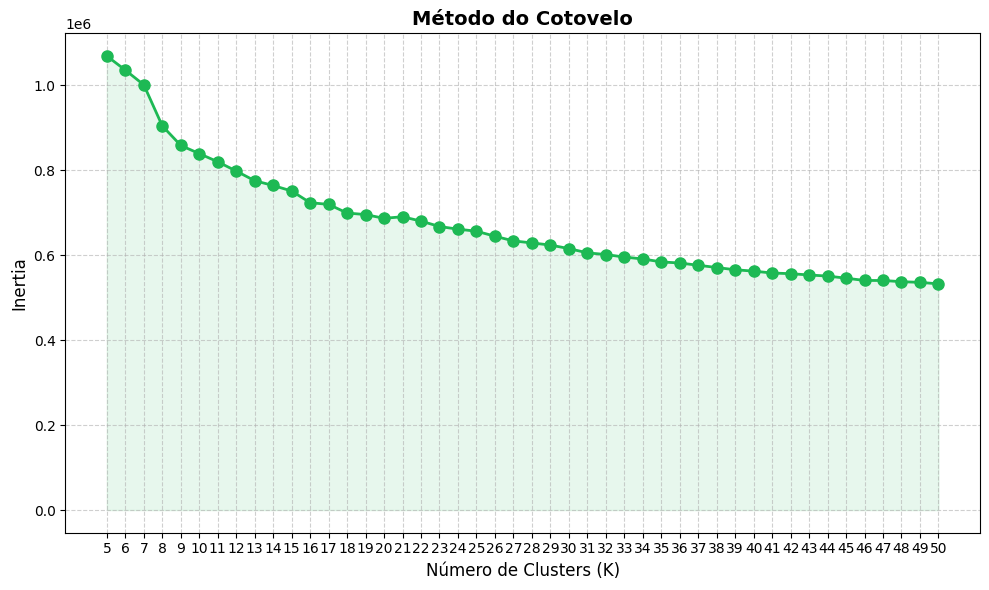

In [13]:
# aplicação do método cotovel de k=[5, 50], demostrando a curva do domínio

def plotar_metodo_cotovelo(X: pd.DataFrame, k_min=5, k_max=50, batch_size=1024):
    """
    testa múltiplos valores de K
    plota o gráfico do Método do Cotovelo usando Inertia.
    """
    try:
        from sklearn.preprocessing import StandardScaler
        from sklearn.cluster import MiniBatchKMeans
        from sklearn.decomposition import PCA
        from sklearn.metrics import silhouette_score
    except ImportError:
        print("Biblioteca scikit-learn não instalada.")
        return None
    
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    pca = PCA(n_components=0.90, random_state=42)
    X_pca = pca.fit_transform(X_scaled)
    
    inertias = []
    sillhoute = []
    k_values = list(range(k_min, k_max + 1))
    
    print(f"Testando valores de K de {k_min} até {k_max}...")
    for k in k_values:
        modelo = MiniBatchKMeans(n_clusters=k, batch_size=batch_size, random_state=42)
        modelo.fit(X_pca)
        labels = modelo.predict(X_pca)
        inertias.append(modelo.inertia_)
        sillhoute.append(silhouette_score(X_pca, labels))
        
    plt.figure(figsize=(10, 6))
    
    plt.plot(k_values, inertias, marker='o', linestyle='-', color='#1DB954', linewidth=2, markersize=8)
    
    plt.title('Método do Cotovelo', fontsize=14, fontweight='bold')
    plt.xlabel('Número de Clusters (K)', fontsize=12)
    plt.ylabel('Inertia', fontsize=12)
    plt.xticks(k_values)
    plt.grid(True, linestyle='--', alpha=0.6)
    
    plt.fill_between(k_values, inertias, color='#1DB954', alpha=0.1)
    
    plt.tight_layout()
    plt.show()

    return


plotar_metodo_cotovelo(df_prep)

## 3.3 Modelagem para agrupamento


In [9]:
# Modelagem para agrupamento: K-Means e DBSCAN
# Adapte os algoritmos conforme a proposta do grupo.

def executar_minibatch_kmeans(X: pd.DataFrame, num_K:int=15, batch_size:int =1024):
    try:
        from sklearn.preprocessing import StandardScaler
        from sklearn.cluster import KMeans, DBSCAN, MiniBatchKMeans
        from sklearn.decomposition import PCA
        from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
    except ImportError:
        print("scikit-learn não está instalado.")
        raise Exception

    start = time.perf_counter()

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    resultados = []
    modelos = {}

    # redução de dimensionalidade com PCA
    pca = PCA(n_components=0.90, random_state=42)
    X_pca = pca.fit_transform(X_scaled)

    modelo = MiniBatchKMeans(n_clusters=num_K, batch_size=batch_size, random_state=42)
    labels = modelo.fit_predict(X_pca)

    nome = "MiniBatchKmeans"
    modelos[nome] = modelo

    end = time.perf_counter()
    tempo = end - start

    resultados.append({
        "modelo": nome,
        "labels": labels,
        "silhouette": silhouette_score(X_pca, labels),
        "davies_bouldin": davies_bouldin_score(X_pca, labels),
        "calinsli_harabasz_score": calinski_harabasz_score(X_pca, labels),
        "inertia": modelo.inertia_,
        "tempo": round(tempo, 6)
    })

    return pd.DataFrame(resultados), modelos

# Exemplo de uso:
def salvar_resultados(resultados: pd.DataFrame, caminho: str = os.path.join(OUTPUT_DIR, "resultados_spotify.csv")):
    #with open(caminho, "w", encoding="utf-8") as f:
    resultados.to_csv(caminho, index=False)
    print(f"Experimentos salvos em: {caminho}")

resultados_cluster, modelos_cluster = executar_minibatch_kmeans(df_prep)
salvar_resultados(resultados_cluster)
display(resultados_cluster)

Experimentos salvos em: outputs/resultados_spotify.csv


,modelo,labels,silhouette,davies_bouldin,calinsli_harabasz_score,inertia,tempo
0,MiniBatchKmeans,"[12, 0, 10, 0, 10, 11, 0, 9, 10, 10, 9, 0, 0, ...",0.100157,1.891937,8108.35105,751075.21836,4.090332


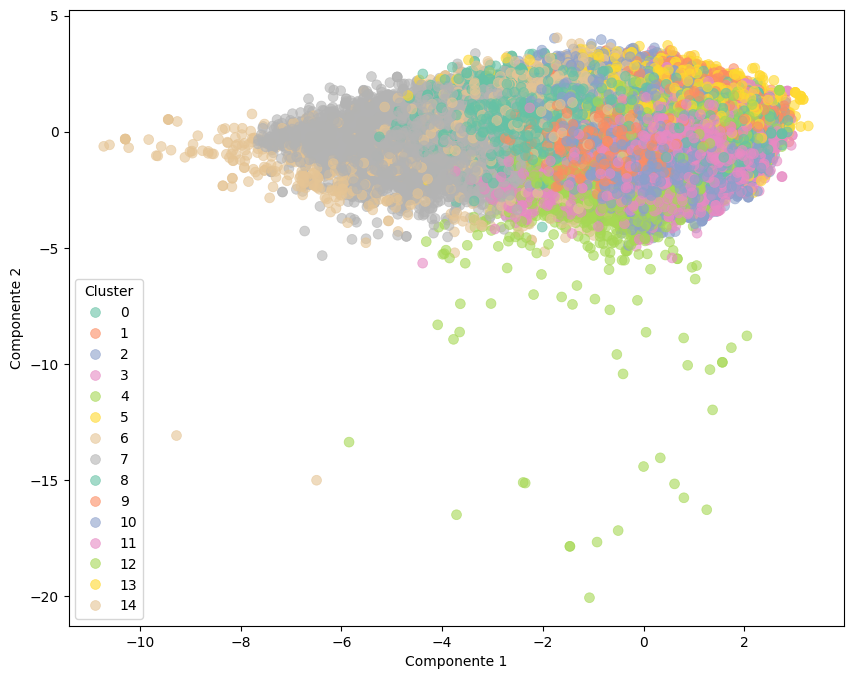

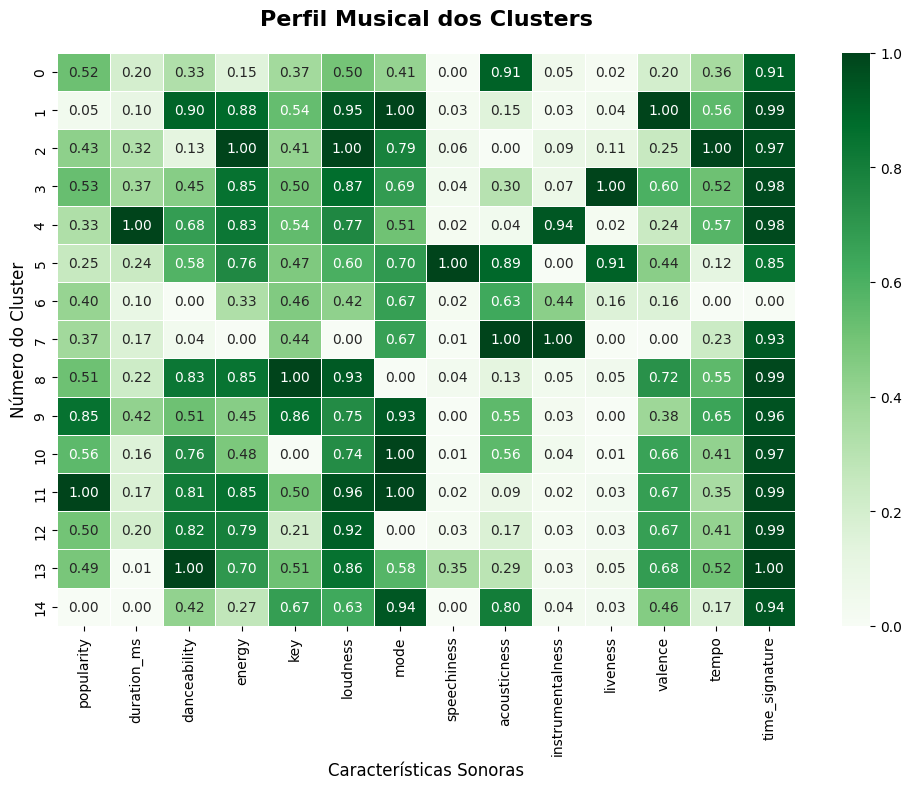

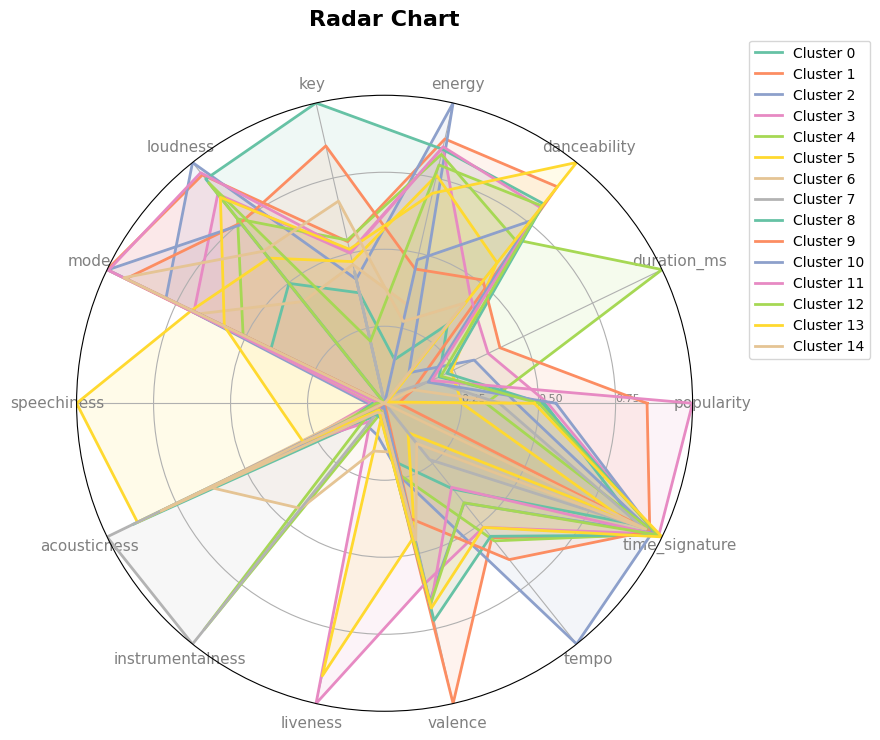

In [11]:
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from math import pi

def plotar_heatmap_clusters(df: pd.DataFrame, labels: np.ndarray):
    """
    Plota um Heatmap com a média de cada cluster
    """

    #df_clusters = df[features].copy()
    df_clusters = df.copy()
    df_clusters['Cluster'] = labels
    
    # média de cada feature
    cluster_means = df_clusters.groupby('Cluster').mean()
    
    # Normalização das médias (transforma os dados para um faixa de 0 a 1)
    scaler = MinMaxScaler()
    cluster_means_scaled = pd.DataFrame(
        scaler.fit_transform(cluster_means), 
        columns=cluster_means.columns, 
        index=cluster_means.index
    )
    
    # Plotagem do Heatmap
    plt.figure(figsize=(10, 8))
    
    sns.heatmap(cluster_means_scaled, annot=True, cmap="Greens", fmt=".2f", linewidths=.5)
    
    plt.title('Perfil Musical dos Clusters', fontsize=16, fontweight='bold', pad=20)
    plt.ylabel('Número do Cluster', fontsize=12)
    plt.xlabel('Características Sonoras', fontsize=12)
    
    plt.tight_layout()
    plt.show()
    
    return cluster_means

def plotar_radar_clusters(df: pd.DataFrame, labels: np.ndarray):
    """
    Plota um Gráfico de Radar
    """
    df_clusters = df.copy()
    df_clusters['Cluster'] = labels
    cluster_means = df_clusters.groupby('Cluster').mean()
    
    scaler = MinMaxScaler()
    cluster_means_scaled = scaler.fit_transform(cluster_means)
    
    N = len(df.columns)
    angulos = [n / float(N) * 2 * pi for n in range(N)]
    angulos += angulos[:1]
    
    plt.figure(figsize=(10, 8))
    ax = plt.subplot(111, polar=True)
    plt.xticks(angulos[:-1], df.columns, color='grey', size=11)
    ax.set_rlabel_position(0)
    plt.yticks([0.25, 0.5, 0.75], ["0.25", "0.50", "0.75"], color="grey", size=8)
    plt.ylim(0, 1)
    cores = plt.cm.Set2.colors
    
    for i in range(len(cluster_means)):
        valores = cluster_means_scaled[i].tolist()
        valores += valores[:1]
        
        ax.plot(angulos, valores, linewidth=2, linestyle='solid', label=f'Cluster {i}', color=cores[i % len(cores)])
        ax.fill(angulos, valores, alpha=0.1, color=cores[i % len(cores)])
        
    plt.title('Radar Chart', size=16, fontweight='bold', y=1.1)
    plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
    
    plt.show()

def plotar_pca_2d(X: pd.DataFrame, labels: np.ndarray):
    """
    Aplica PCA para 2 dimensões e plota.
    """
    try:
        # from sklearn.preprocessing import StandardScaler
        # from sklearn.cluster import MiniBatchKMeans
        from sklearn.preprocessing import StandardScaler    
        from sklearn.decomposition import PCA
    except ImportError:
        print("Biblioteca scikit-learn não instalada.")
        return None
    
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    pca_2d = PCA(n_components=2, random_state=42)
    X_pca_2d = pca_2d.fit_transform(X_scaled)
    
    df_plot = pd.DataFrame({
        'Componente 1': X_pca_2d[:, 0],
        'Componente 2': X_pca_2d[:, 1],
        'Cluster': labels
    })
    
    plt.figure(figsize=(10, 8))
    
    sns.scatterplot(
        x='Componente 1', 
        y='Componente 2',
        hue='Cluster',
        palette='Set2', 
        data=df_plot,
        alpha=0.6,
        s=50,
        edgecolor=None
    )

labels = resultados_cluster['labels'][0]
plotar_pca_2d(df_prep, labels)
plotar_heatmap_clusters(df_prep, labels)
plotar_radar_clusters(df_prep, labels)

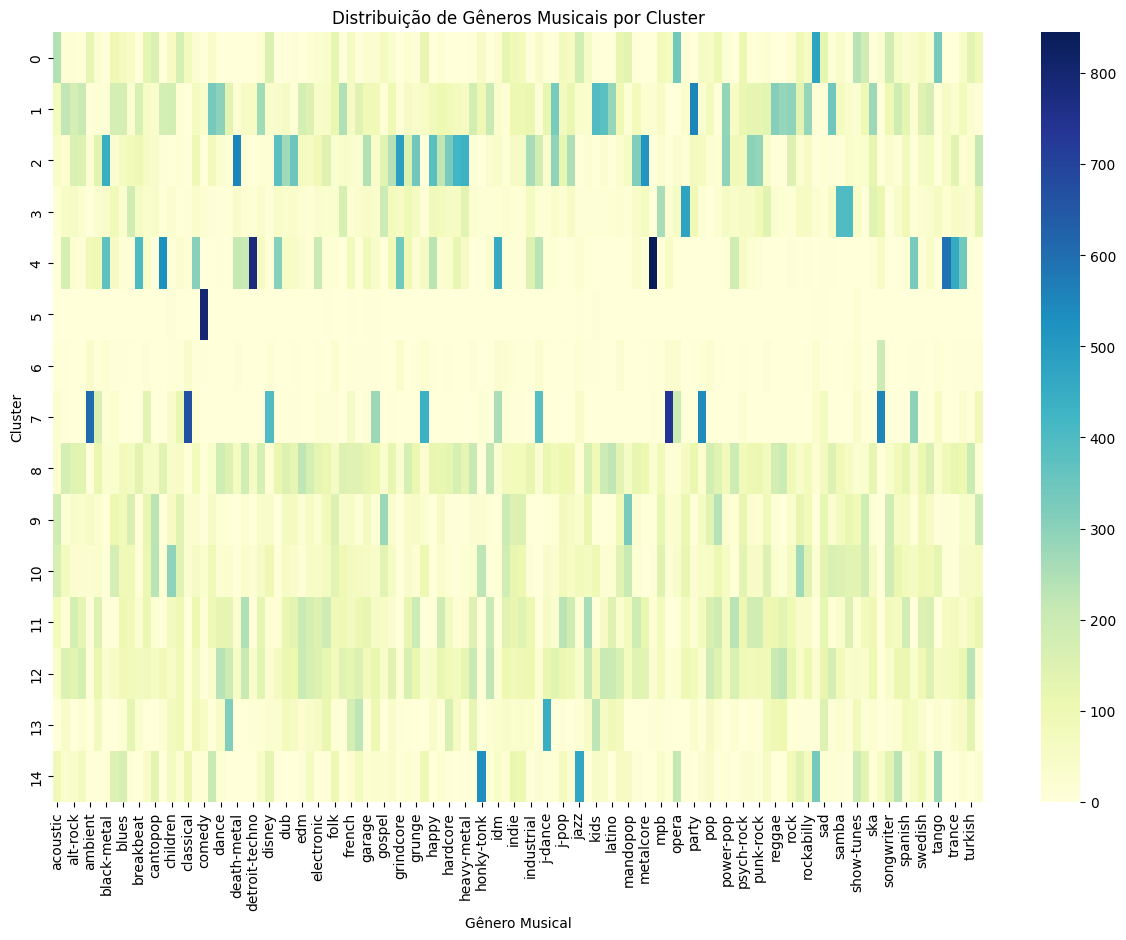

In [12]:
df_clusters = df_prep.copy()
df_clusters['Cluster'] = labels
cluster_means = df_clusters.groupby('Cluster').mean()

tabela_cruzada = pd.crosstab(df_clusters['Cluster'], df['track_genre'])

# Visualizando em formato de Mapa de Calor (Heatmap)
plt.figure(figsize=(15, 10))
sns.heatmap(tabela_cruzada, cmap="YlGnBu")
plt.title("Distribuição de Gêneros Musicais por Cluster")
plt.ylabel("Cluster")
plt.xlabel("Gênero Musical")
plt.show()

## 3.5 Resultados da modelagem final

#### Resultados Quantitativos

| modelo | silhouette | davies_bouldin | calinsli_harabasz_score | inertia | tempo |
| :---  | :--- | :--- | :--- | :--- | :--- |
| MiniBatchKmeans | 0.10015749253472438 | 1.891937361402487 | 8108.35105043306 | 751075.2183600048 | 3.698184 |

#### Visualizações 

![](outputs/pca.png)
![](outputs/heatmap.png)
![](outputs/radar.png)
![](outputs/genre.png)


### Interpretação técnica

Com base nas evidências geradas pelos testes empíricos da modelagem, sustentam-se as seguintes conclusões técnicas verificáveis:

O algoritmo MiniBatchKMeans associado ao pré-processamento por PCA eliminou o gargalo de memória e de tempo esperado para esse tamanho, sustentando um tempo de convergência de 3,698 segundos.

Os scores matemáticos moderados (Silhouette Coefficient de 0,100157 e Davies-Bouldin de 1,891937) comprovam que as variáveis acústicas extraídas das faixas musicais formam um espectro contínuo, tornando agrupamentos espaciais com partições estritas ou isoladas matematicamente irreais para o domínio do Spotify.

A definição de K=15 clusters mitigou a fragmentação excessiva dos agrupamentos sonoras, atuando como um limitador de complexidade para assegurar que os perfis gerados permaneçam acionáveis para tomadores de decisão não técnicos.

A despeito de scores matemáticos, os Gráficos de Radar e a validação externa baseada na distribuição de track_genre atestam, até certo ponto, a existência de coerência interna e separabilidade prática entre os clusters mapeados, isso pode ser visto, por exemplo, no cluster 7 que, de acordo com a distribuição de gênero musicais separou músicas com gêneros similares, como opera, classical e ambient. Contudo, ainda estão presentes limitações claras, como pode ser observado nos cluster 6 e 8, que não conseguiram se distinguir em gêneros definidos.

# 4. Evaluation


## 4.1 Avaliação dos resultados finais

Os resultados obtidos são coerentes com o problema de negócio proposto. O objetivo não era identificar gêneros musicais exatos, mas segmentar faixas com características acústicas semelhantes para apoiar recomendação, curadoria e análise de catálogo. Nesse contexto, os agrupamentos encontrados apresentam utilidade prática, mesmo que as fronteiras entre clusters não sejam perfeitamente definidas.

As métricas utilizadas são adequadas para uma tarefa de agrupamento sem rótulos. O Silhouette Score de aproximadamente 0,10 e o Davies-Bouldin Index de 1,89 indicam separação moderada entre os grupos, enquanto o Calinski-Harabasz Score superior a 8 mil sugere existência de estrutura interna relevante. Embora os valores não indiquem clusters altamente compactos, eles são compatíveis com a natureza contínua das características musicais, em que energia, ritmo, positividade e instrumentalidade variam gradualmente.

As visualizações produzidas (PCA, heatmap, radar e distribuição de gêneros por cluster) demonstram que os grupos possuem perfis acústicos distintos. Além disso, a análise cruzada com `track_genre` mostrou concentrações específicas de gêneros em determinados clusters, fornecendo evidências de que o modelo capturou padrões reais presentes nos dados.

Não há sinais relevantes de overfitting, pois a tarefa é não supervisionada e os agrupamentos foram avaliados por métricas internas. Entretanto, os resultados dependem da escolha de parâmetros como número de clusters, normalização dos dados e variância preservada pelo PCA. Por isso, as conclusões devem ser interpretadas como tendências de segmentação e não como categorias musicais absolutas.

As conclusões são sustentadas pelos dados, pelas métricas obtidas e pela coerência entre os perfis acústicos observados e as distribuições de gêneros presentes nos clusters.


### Limitações dos resultados

- As características musicais formam um espectro contínuo, reduzindo a separação natural entre clusters.
- O algoritmo K-Means assume grupos aproximadamente esféricos, hipótese que pode não representar perfeitamente o espaço acústico.
- A escolha de K=15 influencia diretamente os resultados obtidos.
- Variáveis potencialmente relevantes para recomendação, como contexto de consumo ou comportamento do usuário, não estão presentes no dataset.
- O PCA melhora a eficiência computacional, mas reduz a interpretabilidade direta das componentes utilizadas pelo modelo.
- A variável `track_genre` não foi utilizada no treinamento, servindo apenas como validação externa e interpretação posterior.

## 4.2 Comparação final: baseline × guiada × solução final

| Critério | Baseline sugerida pela LLM | Guiada sugerida pela LLM | Solução final implementada | Avaliação crítica |
|---|---|---|---|---|
| Correção técnica | Correta, porém genérica | Correta e contextualizada | Validada experimentalmente | A solução final combinou a robustez da trilha guiada com validação prática. |
| Adequação ao problema | Parcial | Alta | Alta | A solução final atende diretamente ao objetivo de segmentação acústica. |
| Preparação dos dados | Limpeza e normalização genéricas | Limpeza, normalização e PCA | Limpeza, imputação, normalização e PCA | A implementação seguiu majoritariamente a trilha guiada. |
| Algoritmos escolhidos | K-Means, Hierárquico e DBSCAN | MiniBatchKMeans, GMM e DBSCAN | MiniBatchKMeans | A solução priorizou escalabilidade sem comprometer a qualidade. |
| Métricas de avaliação | Métricas internas de clustering | Mesmas métricas | Silhouette, Davies-Bouldin, Calinski-Harabasz e Inertia | Ambas as trilhas contribuíram igualmente neste aspecto. |
| Interpretabilidade | Médias e visualizações básicas | Heatmap, PCA e radar | Heatmap, PCA, radar e análise de gêneros | A solução ampliou a capacidade de interpretação dos clusters. |
| Rastreabilidade | Justificativas limitadas | Decisões documentadas | Pipeline documentado e reproduzível | A trilha guiada favoreceu maior transparência. |
| Eficiência computacional | Pouca preocupação com escala | Forte foco em escalabilidade | Execução em ~3,7 s para todo o dataset | A diretriz de eficiência influenciou diretamente a implementação. |
| Aderência às diretrizes | Não explícita | Explícita | Incorporada ao pipeline | Houve impacto real das diretrizes nas decisões técnicas. |


### Conclusão da comparação

A comparação evidencia que a trilha baseline foi útil como ponto de partida metodológico, mas apresentou recomendações genéricas e pouco adaptadas às restrições do problema. A trilha guiada produziu sugestões mais alinhadas ao contexto do Spotify, especialmente em eficiência computacional e comunicação dos resultados.

A solução final adotou a maior parte das recomendações da trilha guiada, complementando-as com validação experimental e análise crítica do grupo. Dessa forma, a implementação alcançou melhor equilíbrio entre qualidade analítica, interpretabilidade e custo computacional.


## 4.3 Sugestões aceitas, rejeitadas e corrigidas

| Sugestão | Origem | Decisão | Justificativa |
|---|---|---|---|
| Normalização dos atributos antes do clustering | Baseline | Aceita | Necessária devido às diferentes escalas das variáveis acústicas. |
| Uso de PCA para redução de dimensionalidade | Guiada | Aceita | Reduziu redundâncias e melhorou a eficiência computacional. |
| Utilização de MiniBatchKMeans | Guiada | Aceita | Tornou a solução escalável para mais de 90 mil registros. |
| Avaliação por métricas internas | Baseline | Aceita | Adequada para aprendizado não supervisionado. |
| Uso de Clustering Hierárquico para comparação | Baseline | Rejeitada | Alto custo computacional para o volume de dados analisado. |
| Uso de visualizações para interpretação dos clusters | Guiada | Aceita | Facilitou a comunicação dos resultados para usuários não técnicos. |


### Erros ou limitações das LLMs

| Erro, omissão ou limitação | Trilha | Impacto potencial | Correção feita pelo grupo |
|---|---|---|---|
| Recomendação de algoritmos pouco escaláveis para grandes bases | Baseline | Alto consumo de memória e tempo de execução | Priorização do MiniBatchKMeans com PCA. |
| Respostas excessivamente genéricas | Baseline | Baixa aderência ao contexto do Spotify | Adaptação das recomendações ao domínio musical. |
| Pouca discussão sobre restrições computacionais | Baseline | Possível inviabilidade prática da solução | Inclusão explícita de critérios de eficiência. |
| Ausência de validação empírica dos parâmetros sugeridos | Baseline e Guiada | Escolhas potencialmente inadequadas | Testes experimentais e análise das métricas obtidas. |


## 4.4 Avaliação das diretrizes de IA responsável na solução final

| Diretriz | Como apareceu na Fase 2 | Como foi incorporada na Fase 3 | Evidência no notebook | Limitações |
|---|---|---|---|---|
| Eficiência e escalabilidade | Recomendação de PCA e MiniBatchKMeans | Implementação efetiva do pipeline otimizado | Tempo de execução de aproximadamente 3,7 segundos | Possível perda de informação devido à redução de dimensionalidade. |
| Usabilidade e acessibilidade | Sugestão de visualizações interpretáveis | Uso de heatmap, PCA, radar e análise de gêneros | Visualizações e interpretação dos clusters | Parte da interpretação ainda exige conhecimento técnico. |


### Discussão crítica

As diretrizes influenciaram não apenas a redação do trabalho, mas também decisões concretas do pipeline. A diretriz de eficiência alterou diretamente a arquitetura da solução, motivando a utilização de PCA e MiniBatchKMeans em vez de algoritmos mais custosos.

A diretriz de usabilidade também teve impacto prático ao incentivar a criação de visualizações que permitem interpretar os clusters além das métricas numéricas. Isso tornou os resultados mais úteis para equipes de negócio, como curadoria de playlists e recomendação.

Em ambos os casos houve trade-offs. O PCA reduz a interpretabilidade direta dos atributos originais, enquanto a produção de visualizações aumenta a complexidade da análise. Ainda assim, os benefícios superaram os custos observados.


## 4.5 Trade-offs finais

| Trade-off | Evidência observada | Decisão final | Justificativa |
|---|---|---|---|
| Desempenho × interpretabilidade | PCA reduz dimensionalidade, mas dificulta interpretação direta | Priorizar desempenho | Necessário para processar o dataset de forma eficiente. |
| Eficiência × qualidade dos resultados | Algoritmos mais sofisticados poderiam melhorar métricas | Priorizar eficiência | Ganho computacional justificou a escolha. |
| Simplicidade × completude da análise | Mais modelos aumentariam a cobertura analítica | Focar em um pipeline principal | Permitiu análise mais consistente e reproduzível. |

### Síntese

O principal trade-off identificado foi entre qualidade geométrica dos agrupamentos e eficiência computacional. A adoção de PCA e MiniBatchKMeans reduziu significativamente o custo de processamento, permitindo trabalhar com uma base de grande porte de forma viável. Em contrapartida, os clusters apresentam separação moderada, refletida nas métricas obtidas.

Também houve um trade-off entre interpretabilidade e desempenho. Embora a redução de dimensionalidade dificulte a explicação detalhada das componentes internas do modelo, ela foi essencial para garantir escalabilidade. Considerando os objetivos do projeto, as decisões adotadas produziram o melhor equilíbrio entre utilidade prática, desempenho e capacidade de interpretação.


# 5. Conclusão

Neste trabalho, investigamos a segmentação de músicas do Spotify por meio de técnicas de aprendizado não supervisionado aplicadas ao Spotify Tracks Dataset. Após comparar as sugestões geradas pelas LLMs nas condições baseline e guiada, implementamos uma solução baseada em normalização dos dados, redução de dimensionalidade com PCA e agrupamento utilizando MiniBatchKMeans.

Os resultados mostraram que é possível identificar grupos de músicas com perfis acústicos distintos, corroborados tanto pelas métricas de clustering quanto pelas análises visuais e pela distribuição de gêneros entre os clusters. Embora as métricas indiquem separação moderada entre os grupos, os agrupamentos obtidos são consistentes com a natureza contínua das características musicais.

Entre as principais limitações estão a dependência da escolha do número de clusters, as restrições do algoritmo K-Means e a ausência de informações contextuais sobre o consumo das músicas. Além disso, a redução de dimensionalidade melhora o desempenho, mas reduz parte da interpretabilidade do modelo.

As LLMs contribuíram como apoio ao planejamento e à tomada de decisões, sendo que a versão guiada por diretrizes produziu recomendações mais alinhadas ao problema. As diretrizes de IA responsável, especialmente eficiência e usabilidade, tiveram impacto direto na solução final, influenciando a escolha dos algoritmos e a forma de apresentação dos resultados.

Como trabalhos futuros, podem ser explorados outros algoritmos de clustering, métodos de seleção automática de clusters e a incorporação de informações adicionais para enriquecer a análise. Em conjunto, os resultados demonstram que o uso combinado de técnicas de clustering e assistência de LLMs pode apoiar de forma eficaz a segmentação musical em larga escala.


# 6. Referências

**Data Mining and Machine Learning: Fundamental Concepts and Algorithms**  
Second Edition  
*Mohammed J. Zaki and Wagner Meira, Jr*  
Cambridge University Press, March 2020  
Disponível em: https://dataminingbook.info/